# Section 4 — Figures and assembly

Most of your figures already exist - they were produced by Sections 1-3. This notebook:

1. **Inventories** every figure and flags anything missing
2. **Builds `sensors_for_gephi.csv`** so you can highlight sensors in Gephi
   (Section 3 works in usernames, Gephi works in hashes - this bridges them)
3. **Generates a summary panel** combining the headline results
4. **Writes a caption sheet** you can paste into the report

The three network visuals (4.1-4.3) are Gephi work - steps are in the final cell.

In [2]:
import os, json, csv
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi":120,"savefig.dpi":300,"font.size":10})

EXPECTED = {
 "fig_A_degree_distribution.png":      "S1 Block A - degree distribution + log-log",
 "fig_D_centrality_correlation.png":   "S1 Block D - centrality correlation heatmap",
 "fig_E_seed_communities.png":         "S1 Block E - seeds across communities",
 "fig_E_centrality_vs_spread.png":     "S1 Block E - centrality vs actual spread",
 "fig_E_redundancy.png":               "S1 Block E - redundancy / submodularity",
 "fig1_spread_vs_k.png":               "S2 - influence spread by algorithm",
 "fig2_celf_vs_greedy.png":            "S2 - CELF vs Greedy cost",
 "fig3_seed_overlap.png":              "S2 - seed overlap with centralities",
 "fig_all_families.png":               "S2b - all three algorithm families",
 "fig_detection_vs_k.png":             "S3a - detection rate / delay / precision",
 "fig_leadtime_precision.png":         "S3a - lead time + precision trade-off",
 "fig_APP3_validation.png":            "S3b - arrival position validation",
 "fig_APP4_sensor_communities.png":    "S3b - sensors across communities",
}
print(f"{'status':<8} {'figure':<38} description")
missing=[]
for f,desc in EXPECTED.items():
    ok=os.path.exists(f"figures/{f}")
    if not ok: missing.append(f)
    print(f"{'OK' if ok else 'MISSING':<8} {f:<38} {desc}")
print(f"\n{len(EXPECTED)-len(missing)}/{len(EXPECTED)} figures present")
if missing:
    print("missing -> re-run the notebook that produces it:")
    for m in missing: print(f"   {m}  ({EXPECTED[m]})")

status   figure                                 description
OK       fig_A_degree_distribution.png          S1 Block A - degree distribution + log-log
OK       fig_D_centrality_correlation.png       S1 Block D - centrality correlation heatmap
OK       fig_E_seed_communities.png             S1 Block E - seeds across communities
OK       fig_E_centrality_vs_spread.png         S1 Block E - centrality vs actual spread
OK       fig_E_redundancy.png                   S1 Block E - redundancy / submodularity
OK       fig1_spread_vs_k.png                   S2 - influence spread by algorithm
OK       fig2_celf_vs_greedy.png                S2 - CELF vs Greedy cost
OK       fig3_seed_overlap.png                  S2 - seed overlap with centralities
OK       fig_all_families.png                   S2b - all three algorithm families
OK       fig_detection_vs_k.png                 S3a - detection rate / delay / precision
OK       fig_leadtime_precision.png             S3a - lead time + precision trade-

## 4.1 — Build the Gephi sensor file

Section 3 produced `data/sensors.csv` keyed by **username**. Gephi needs **hashes**.
This writes `sensors_for_gephi.csv` which you import the same way you imported `celf_seeds.csv`.

In [3]:
h2u=json.load(open("username_mapping_v3_PRIVATE.json"))
u2h={v:k for k,v in h2u.items()}

sensors=[r["sensor"] for r in csv.DictReader(open("data/sensors.csv"))]
print(f"{len(sensors)} sensors from Section 3")

rows=[]; matched=0
for h,u in h2u.items():
    if u in sensors:
        rank=len(sensors)-sensors.index(u)
        rows.append({"Id":h,"is_sensor":"SENSOR","sensor_rank":rank}); matched+=1
    else:
        rows.append({"Id":h,"is_sensor":"not_sensor","sensor_rank":0})
pd.DataFrame(rows).to_csv("sensors_for_gephi.csv",index=False)
print(f"wrote sensors_for_gephi.csv ({len(rows):,} rows, {matched} marked SENSOR)")
if matched!=len(sensors):
    print(f"  note: {len(sensors)-matched} sensors had no hash mapping")

20 sensors from Section 3
wrote sensors_for_gephi.csv (6,434 rows, 20 marked SENSOR)


## 4.2 — Summary panel

One figure combining the headline numbers. Useful for a presentation slide or the report's
results overview.

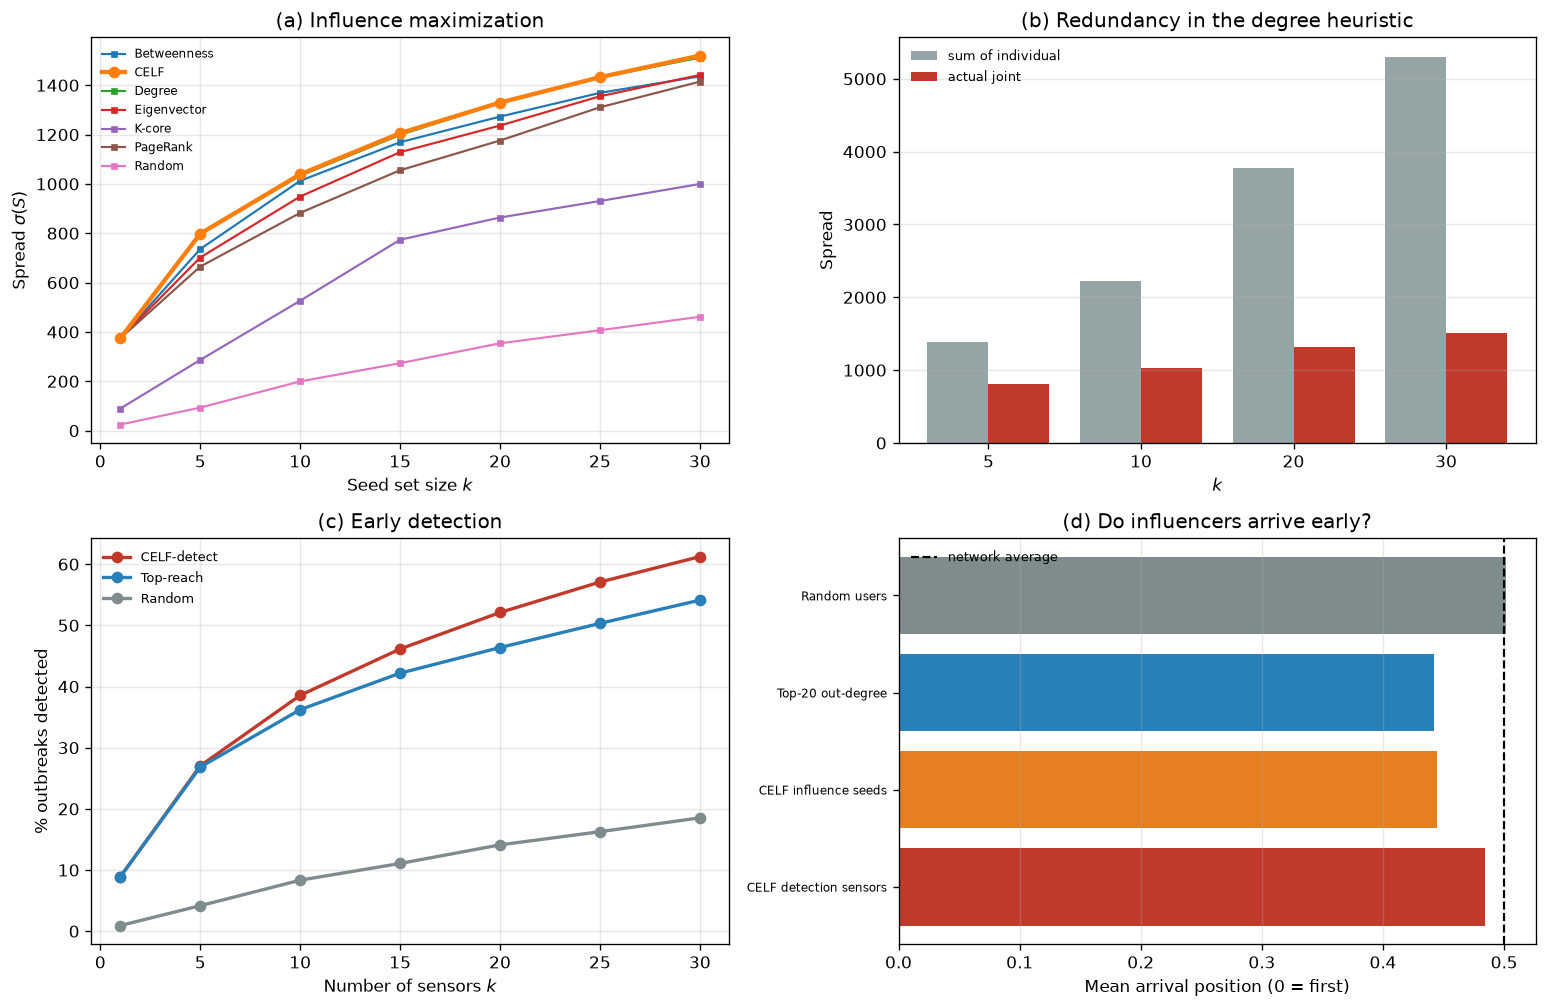

saved figures/fig_SUMMARY_panel.png


In [4]:
fig,ax=plt.subplots(2,2,figsize=(13,8.5))

# (a) influence: spread vs k
try:
    r=pd.read_csv("im_results.csv")
    p=r.pivot_table(index="k",columns="algorithm",values="spread")
    for alg in p.columns:
        lw,z=(2.6,5) if alg=="CELF" else (1.3,2)
        ax[0,0].plot(p.index,p[alg],label=alg,lw=lw,zorder=z,
                     marker="o" if alg=="CELF" else "s",ms=6 if alg=="CELF" else 3)
    ax[0,0].set_xlabel("Seed set size $k$"); ax[0,0].set_ylabel(r"Spread $\sigma(S)$")
    ax[0,0].set_title("(a) Influence maximization"); ax[0,0].legend(frameon=False,fontsize=7)
    ax[0,0].grid(alpha=.3)
except FileNotFoundError:
    ax[0,0].text(.5,.5,"im_results.csv missing",ha="center"); ax[0,0].axis("off")

# (b) redundancy
try:
    red=pd.read_csv("figures/blockE_redundancy.csv")
    x=np.arange(len(red))
    ax[0,1].bar(x-0.2,red.sum_individual,0.4,label="sum of individual",color="#95a5a6")
    ax[0,1].bar(x+0.2,red.joint_spread,0.4,label="actual joint",color="#c0392b")
    ax[0,1].set_xticks(x); ax[0,1].set_xticklabels(red.k)
    ax[0,1].set_xlabel("$k$"); ax[0,1].set_ylabel("Spread")
    ax[0,1].set_title("(b) Redundancy in the degree heuristic")
    ax[0,1].legend(frameon=False,fontsize=8); ax[0,1].grid(alpha=.3,axis="y")
except FileNotFoundError:
    ax[0,1].text(.5,.5,"blockE_redundancy.csv missing",ha="center"); ax[0,1].axis("off")

# (c) detection
try:
    d=pd.read_csv("data/detection_results.csv")
    for alg,col in [("CELF-detect","#c0392b"),("Top-reach","#2980b9"),("Random","#7f8c8d")]:
        s=d[d.algorithm==alg].sort_values("k")
        ax[1,0].plot(s.k,100*s.detection_rate,label=alg,color=col,marker="o",lw=2)
    ax[1,0].set_xlabel("Number of sensors $k$"); ax[1,0].set_ylabel("% outbreaks detected")
    ax[1,0].set_title("(c) Early detection"); ax[1,0].legend(frameon=False,fontsize=8)
    ax[1,0].grid(alpha=.3)
except FileNotFoundError:
    ax[1,0].text(.5,.5,"detection_results.csv missing",ha="center"); ax[1,0].axis("off")

# (d) arrival position
try:
    a=pd.read_csv("figures/blockAPP3_arrival_position.csv")
    yy=np.arange(len(a))
    ax[1,1].barh(yy,a.mean_position,color=["#c0392b","#e67e22","#2980b9","#7f8c8d"][:len(a)])
    ax[1,1].axvline(0.5,color="black",ls="--",lw=1.3,label="network average")
    ax[1,1].set_yticks(yy); ax[1,1].set_yticklabels(a.group,fontsize=7)
    ax[1,1].set_xlabel("Mean arrival position (0 = first)")
    ax[1,1].set_title("(d) Do influencers arrive early?")
    ax[1,1].legend(frameon=False,fontsize=8); ax[1,1].grid(alpha=.3,axis="x")
except FileNotFoundError:
    ax[1,1].text(.5,.5,"blockAPP3_arrival_position.csv missing",ha="center"); ax[1,1].axis("off")

plt.tight_layout(); plt.savefig("figures/fig_SUMMARY_panel.png",bbox_inches="tight"); plt.show()
print("saved figures/fig_SUMMARY_panel.png")

## 4.3 — Caption sheet

In [5]:
caps = {
"fig_A_degree_distribution.png":
  "Degree distribution of the Hacker News interaction network (n=6,434). Left: histogram showing "
  "strong right skew (mean 80.55, median 30). Right: log-log plot with power-law fit.",
"fig_D_centrality_correlation.png":
  "Spearman rank correlation between centrality measures. High correlation between degree and "
  "k-core indicates they capture similar structural roles.",
"fig_E_redundancy.png":
  "Redundancy in the degree heuristic. Left: summed individual spread versus actual joint spread "
  "for the top-k highest out-degree users. Right: proportion of influence lost to audience overlap, "
  "rising with k - a direct empirical demonstration of submodularity.",
"fig_E_centrality_vs_spread.png":
  "Correlation of each centrality measure against simulated influence spread. No measure exceeds "
  "rho=0.85, and PageRank performs worst because it tracks in-degree rather than out-degree.",
"fig1_spread_vs_k.png":
  "Expected influence spread by seed-selection algorithm under the Independent Cascade model with "
  "Weighted Cascade probabilities.",
"fig2_celf_vs_greedy.png":
  "Computational cost of CELF versus plain Greedy at equal k. Both return identical seed sets; "
  "CELF requires substantially fewer spread evaluations.",
"fig_all_families.png":
  "All three algorithm families from the Li et al. taxonomy: simulation-based (CELF), proxy-based "
  "(centrality heuristics) and sketch-based (RIS).",
"fig_detection_vs_k.png":
  "Early-detection performance versus number of sensors. Left: proportion of significant "
  "discussions detected. Centre: mean detection delay. Right: precision.",
"fig_leadtime_precision.png":
  "Left: distribution of lead time before a discussion reaches half its activity. Right: "
  "coverage versus alert-quality trade-off as sensor count increases.",
"fig_APP3_validation.png":
  "Validation against observed cascades. Left: mean arrival position (0 = first to comment). "
  "Right: mean number of discussions joined.",
"fig_APP4_sensor_communities.png":
  "Distribution of selected sensors across Louvain communities, against proportional expectation.",
"fig_SUMMARY_panel.png":
  "Summary of principal results: (a) influence maximization, (b) heuristic redundancy, "
  "(c) early detection, (d) cascade validation.",
"GEPHI_full_network.png":
  "Hacker News interaction network (6,434 users, 259,122 weighted edges), ForceAtlas2 layout, "
  "nodes coloured by Louvain community and sized by degree.",
"GEPHI_core_subgraph.png":
  "High-degree core of the network, filtered to nodes with degree above threshold, revealing "
  "structure obscured in the full view.",
"GEPHI_sensors_highlighted.png":
  "Network with the CELF-selected monitoring sensors highlighted, showing their distribution "
  "across the network rather than concentration in a single region.",
}
with open("figures/FIGURE_CAPTIONS.md","w") as f:
    f.write("# Figure captions\n\n")
    for i,(k,v) in enumerate(caps.items(),1):
        exists="" if os.path.exists(f"figures/{k}") else "  *(not yet produced)*"
        f.write(f"**Figure {i}** - `{k}`{exists}\n\n{v}\n\n")
        print(f"Figure {i:>2}: {k}")
print("\nsaved figures/FIGURE_CAPTIONS.md")

Figure  1: fig_A_degree_distribution.png
Figure  2: fig_D_centrality_correlation.png
Figure  3: fig_E_redundancy.png
Figure  4: fig_E_centrality_vs_spread.png
Figure  5: fig1_spread_vs_k.png
Figure  6: fig2_celf_vs_greedy.png
Figure  7: fig_all_families.png
Figure  8: fig_detection_vs_k.png
Figure  9: fig_leadtime_precision.png
Figure 10: fig_APP3_validation.png
Figure 11: fig_APP4_sensor_communities.png
Figure 12: fig_SUMMARY_panel.png
Figure 13: GEPHI_full_network.png
Figure 14: GEPHI_core_subgraph.png
Figure 15: GEPHI_sensors_highlighted.png

saved figures/FIGURE_CAPTIONS.md


## 4.4 - 4.6 — The three Gephi figures

These are GUI work. Your Gephi project already has the layout, communities and statistics.

### Figure: full network
1. **Appearance -> Nodes -> Color -> Partition -> Modularity Class** -> Generate -> Apply
2. **Appearance -> Nodes -> Size -> Ranking -> Degree** -> Min 2, Max 40, spline -> Apply
3. **Preview** tab: edge opacity **5-10**, edge thickness 0.1, labels OFF
4. **Export -> PNG**, width **3500 px** (not PDF - 259k vector paths will hang)
5. Save as `figures/GEPHI_full_network.png`

### Figure: core subgraph
1. **Filters -> Topology -> Degree Range** -> drag to the query box
2. Set minimum to about **150-200** -> Filter
3. Re-run **ForceAtlas 2** briefly so the subgraph settles
4. Labels ON (they are readable at this size)
5. Export PNG -> `figures/GEPHI_core_subgraph.png`
6. **Reset the filter afterwards**

### Figure: sensors highlighted
1. **Data Laboratory -> Import Spreadsheet** -> `sensors_for_gephi.csv` -> **Nodes table**
   -> **Append to existing workspace**
2. **Appearance -> Nodes -> Color -> Partition -> is_sensor**: SENSOR = red, not_sensor = pale grey
3. **Appearance -> Nodes -> Size -> Ranking -> sensor_rank** -> Min 8, Max 70
4. Filter **sensor_rank > 0** if you want labels on sensors only
5. Export PNG -> `figures/GEPHI_sensors_highlighted.png`

**Reminder:** untick "Visible graph only" in Data Laboratory settings before exporting tables,
and clear filters before a full-network export.